# Ensemble Learning on Sri Lankan Used-Car Prices
### Bagging, Boosting, Stacking, and a Random Forest + ANN hybrid

**Name,** Serasinghe S T H C H
**Index,** 224179H
**Module,** CM3720 Machine Learning (L4S1) - Hands-On Ensemble Learning Project

I predict used-car prices from Sri Lankan adverts and compare four ensemble methods, **bagging** (Random Forest), **boosting** (XGBoost, LightGBM, CatBoost), **stacking**, and a **hybrid Random Forest + ANN**.

Every model uses the same preprocessing and the same train/test split. I tune with `GridSearchCV`, say why I chose the metric, and save the models for the Streamlit dashboard (`app.py`).

1. Setup and dataset
2. Data checks and EDA
3. Preprocessing and metrics
4. Baselines (bias and variance)
5. Bagging and Random Forest
6. Boosting
7. Stacking
8. Hybrid RF + ANN
9. Final comparison
10. Feature importance
11. Discussion
12. Saving the models
13. AI usage and references


## 1. Setup and dataset

In [1]:
import os, time, json, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import make_scorer, mean_squared_error
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
SEED = 42
np.random.seed(SEED)
QUICK = os.environ.get("QUICK_RUN") == "1"   # only used by me to smoke-test the notebook on a small sample
os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

### Shared helper module
The saved pipelines contain my feature function and the hybrid class, so those have to live in a file that can be imported. Otherwise `pickle` cannot load the models in the dashboard. The next cell writes `ensemble_utils.py`.


In [2]:
%%writefile ensemble_utils.py
"""
ensemble_utils.py
-----------------
Helper code shared by the notebook and the Streamlit dashboard.

Author : Serasinghe S T H C H (224179H)
Project: Ensemble learning on Sri Lankan used-car prices

Everything the saved .pkl models need at prediction time (feature
engineering + the RF+ANN hybrid class) lives here, so the pickles can be
loaded anywhere as long as this file is importable.
"""
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# ---------------------------------------------------------------------------
# Constants
# ---------------------------------------------------------------------------
REFERENCE_YEAR = 2025          # listings were scraped Dec-2024 to Feb-2025
SEED = 42

# raw columns that the user (or the dashboard) has to provide
RAW_COLS = ["Brand", "Model", "YOM", "Engine_cc", "Gear", "Fuel", "Town",
            "Leasing", "Condition", "AC", "PowerSteering", "PowerMirror",
            "PowerWindow"]

CAT_COLS = ["Brand", "Model", "Town", "Gear", "Fuel", "Leasing", "Condition"]
NUM_COLS = ["Age", "Engine_cc", "AC", "PowerSteering", "PowerMirror",
            "PowerWindow", "EquipScore"]


# ---------------------------------------------------------------------------
# Data loading / cleaning
# ---------------------------------------------------------------------------
def load_and_clean(path):
    """Read the Kaggle csv and return a tidy dataframe (Price in LKR lakhs)."""
    df = pd.read_csv(path)
    df = df.rename(columns={
        "Engine (cc)": "Engine_cc", "Fuel Type": "Fuel",
        "AIR CONDITION": "AC", "POWER STEERING": "PowerSteering",
        "POWER MIRROR": "PowerMirror", "POWER WINDOW": "PowerWindow",
        "Millage(KM)": "Mileage_km",
    })
    return df


def add_features(X):
    """
    Feature engineering that is applied *inside* every pipeline.
    Input : raw columns (see RAW_COLS)
    Output: CAT_COLS + NUM_COLS
    """
    X = pd.DataFrame(X).copy()
    X["Age"] = (REFERENCE_YEAR - X["YOM"].astype(float)).clip(lower=0)
    for c in ["AC", "PowerSteering", "PowerMirror", "PowerWindow"]:
        X[c] = (X[c].astype(str).str.lower() == "available").astype(int)
    X["EquipScore"] = X[["AC", "PowerSteering", "PowerMirror", "PowerWindow"]].sum(axis=1)
    X["Engine_cc"] = X["Engine_cc"].astype(float)
    for c in CAT_COLS:
        X[c] = X[c].astype(str)
    return X[CAT_COLS + NUM_COLS]


# ---------------------------------------------------------------------------
# Pipelines
# ---------------------------------------------------------------------------
def make_preprocessor(scale=False, min_freq=10):
    """
    One-hot encode the categoricals (rare levels are pooled into one
    'infrequent' bucket so the 1500+ car models do not explode the width)
    and optionally standardise the numeric columns (needed for SVR / ANN,
    NOT needed for trees).
    """
    num_steps = [("imp", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                  min_frequency=min_freq, sparse_output=False)),
        ]), CAT_COLS),
        ("num", Pipeline(num_steps), NUM_COLS),
    ])


def make_pipe(estimator, scale=False, log_target=True):
    """
    raw columns -> feature engineering -> preprocessing -> model.
    The target is modelled as log(1+price) and converted back automatically,
    so .predict() always returns the price in LKR lakhs.
    """
    pipe = Pipeline([
        ("fe", FunctionTransformer(add_features)),
        ("pre", make_preprocessor(scale=scale)),
        ("model", estimator),
    ])
    if not log_target:
        return pipe
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p,
                                      inverse_func=np.expm1)


def native_cat_preprocessor():
    """Pass raw categorical strings straight through (for CatBoost)."""
    return ColumnTransformer([
        ("cat", "passthrough", CAT_COLS),
        ("num", SimpleImputer(strategy="median"), NUM_COLS),
    ]).set_output(transform="pandas")


class NativeCatBoost(BaseEstimator, RegressorMixin):
    """
    Thin wrapper so CatBoost can use its *native* categorical handling
    (ordered target statistics) inside an sklearn pipeline. CatBoost's own
    `cat_features` argument does not survive sklearn's clone(), hence this.
    Expects the DataFrame produced by native_cat_preprocessor().
    """

    def __init__(self, iterations=800, learning_rate=0.05, depth=6,
                 l2_leaf_reg=3.0, random_state=SEED):
        self.iterations = iterations
        self.learning_rate = learning_rate
        self.depth = depth
        self.l2_leaf_reg = l2_leaf_reg
        self.random_state = random_state

    def _cat_idx(self, X):
        return [i for i, c in enumerate(X.columns) if c.split("__")[-1] in CAT_COLS]

    def fit(self, X, y):
        from catboost import CatBoostRegressor
        self.model_ = CatBoostRegressor(
            iterations=self.iterations, learning_rate=self.learning_rate,
            depth=self.depth, l2_leaf_reg=self.l2_leaf_reg,
            random_seed=self.random_state, verbose=0, thread_count=-1)
        self.model_.fit(X, y, cat_features=self._cat_idx(X))
        return self

    def predict(self, X):
        return self.model_.predict(X)


def make_native_catboost_pipe(**kwargs):
    pipe = Pipeline([
        ("fe", FunctionTransformer(add_features)),
        ("pre", native_cat_preprocessor()),
        ("model", NativeCatBoost(**kwargs)),
    ])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p,
                                      inverse_func=np.expm1)


# ---------------------------------------------------------------------------
# Hybrid model, Random Forest + ANN
# ---------------------------------------------------------------------------
class RFANNHybrid(BaseEstimator, RegressorMixin):
    """
    Hybrid of a Random Forest (bagging) and an ANN (MLP), three flavours:

    mode="blend"      RF and ANN are trained independently on log(price);
                      prediction = w * RF + (1 - w) * ANN.
    mode="residual"   ANN is trained on the RF's *out-of-bag* residuals
                      (true - OOB prediction) and added back on top of the RF.
                      OOB predictions are honest because each tree never saw
                      that row, so there is no leakage.
    mode="rf_feature" ANN gets the scaled features PLUS the RF's OOB prediction
                      as an extra input (RF output feeds the ANN).

    Works on the log(price) scale; wrap with make_hybrid_pipe() to get lakhs.
    """

    def __init__(self, mode="blend", n_estimators=300, max_features=0.33,
                 min_samples_leaf=1, hidden_layer_sizes=(64, 32), alpha=1e-3,
                 rf_weight=0.5, ann_weight=1.0, n_ann=1, random_state=SEED):
        self.mode = mode
        self.n_estimators = n_estimators
        self.max_features = max_features
        self.min_samples_leaf = min_samples_leaf
        self.hidden_layer_sizes = hidden_layer_sizes
        self.alpha = alpha
        self.rf_weight = rf_weight
        self.ann_weight = ann_weight
        self.n_ann = n_ann
        self.random_state = random_state

    def _new_ann(self, seed):
        return MLPRegressor(
            hidden_layer_sizes=self.hidden_layer_sizes, alpha=self.alpha,
            early_stopping=True, validation_fraction=0.15, n_iter_no_change=15,
            max_iter=400, random_state=seed)

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y, dtype=float)
        self.rf_ = RandomForestRegressor(
            n_estimators=self.n_estimators, max_features=self.max_features,
            min_samples_leaf=self.min_samples_leaf, oob_score=True,
            n_jobs=-1, random_state=self.random_state).fit(X, y)
        oob = self.rf_.oob_prediction_
        Xs = X   # numeric columns are already standardised by the preprocessor
        if self.mode == "residual":
            target, Z = y - oob, Xs
        elif self.mode == "rf_feature":
            target, Z = y, np.column_stack([Xs, (oob - y.mean()) / y.std()])
            self.y_mean_, self.y_std_ = y.mean(), y.std()
        else:  # blend
            target, Z = y, Xs
        # n_ann > 1 -> a small bag of ANNs with different seeds (variance reduction)
        self.anns_ = [self._new_ann(self.random_state + i).fit(Z, target)
                      for i in range(self.n_ann)]
        return self

    def _ann_predict(self, X):
        Xs = X
        if self.mode == "rf_feature":
            rf_p = (self.rf_.predict(X) - self.y_mean_) / self.y_std_
            Xs = np.column_stack([Xs, rf_p])
        return np.mean([a.predict(Xs) for a in self.anns_], axis=0)

    def predict_rf(self, X):
        return self.rf_.predict(np.asarray(X))

    def predict_ann(self, X):
        X = np.asarray(X)
        p = self._ann_predict(X)
        return p

    def predict(self, X):
        X = np.asarray(X)
        rf_p = self.rf_.predict(X)
        ann_p = self._ann_predict(X)
        if self.mode == "residual":
            return rf_p + self.ann_weight * ann_p
        if self.mode == "rf_feature":
            return ann_p
        return self.rf_weight * rf_p + (1 - self.rf_weight) * ann_p

def make_hybrid_pipe(**kwargs):
    pipe = Pipeline([
        ("fe", FunctionTransformer(add_features)),
        ("pre", make_preprocessor(scale=True)),   # RF is invariant to scaling
        ("model", RFANNHybrid(**kwargs)),
    ])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p,
                                      inverse_func=np.expm1)


# ---------------------------------------------------------------------------
# Evaluation helper
# ---------------------------------------------------------------------------
def evaluate(y_true, y_pred):
    """Metrics on the original scale (LKR lakhs)."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": r2_score(y_true, y_pred),
        "MAPE_%": float(np.mean(np.abs(y_true - y_pred) / y_true) * 100),
        "RMSLE": float(np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred)))),
    }

Overwriting ensemble_utils.py


In [3]:
import importlib, ensemble_utils as eu
importlib.reload(eu)

<module 'ensemble_utils' from 'C:\\UOM- IT\\L4S1\\ML\\Assignment 1\\sl-car-price-ensemble\\ensemble_utils.py'>

### The dataset
**Source,** SriLankan Vehicle (Car) Price Dataset by P. Nirmal, Kaggle
(https://www.kaggle.com/datasets/prasadnirmal/srilankan-second-vehiclecar-price-dataset), MIT licence.
9,788 used-car adverts from **ikman.lk** and **riyasewana.com**, December 2024 to February 2025.

Why this dataset,
* It is Sri Lankan (local brands, towns, prices in LKR), not a US dataset.
* `Price` is continuous, so this is tabular regression. A **Random Forest + ANN** hybrid fits that.
* It mixes numbers with categories that have many levels (1,555 models, 107 towns).


In [4]:
DATA_PATH = "data/car_price_dataset.csv"
raw = eu.load_and_clean(DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Shape: (9788, 17)


,Unnamed: 0,Brand,Model,YOM,Engine_cc,Gear,Fuel,Mileage_km,Town,Date,Leasing,Condition,AC,PowerSteering,PowerMirror,PowerWindow,Price
0,0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0
1,1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0
2,2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5
3,3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0
4,4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5


## 2. Data quality checks and EDA

In [5]:
print(raw.dtypes, "\n")
print("Missing values per column:\n", raw.isna().sum().to_string(), "\n")
raw.describe().T

Unnamed: 0         int64
Brand             object
Model             object
YOM                int64
Engine_cc        float64
Gear              object
Fuel              object
Mileage_km       float64
Town              object
Date              object
Leasing           object
Condition         object
AC                object
PowerSteering     object
PowerMirror       object
PowerWindow       object
Price            float64
dtype: object 

Missing values per column:
 Unnamed: 0       0
Brand            0
Model            0
YOM              0
Engine_cc        0
Gear             0
Fuel             0
Mileage_km       0
Town             0
Date             0
Leasing          0
Condition        0
AC               0
PowerSteering    0
PowerMirror      0
PowerWindow      0
Price            0 



,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,9788.0,4893.758991,2826.028988,0.00,2446.75,4893.5,7341.25,9788.0
YOM,9788.0,2006.759093,9.831574,1956.00,2001.00,2009.0,2015.00,2024.0
Engine_cc,9788.0,1260.442358,403.769059,573.00,1000.00,1300.0,1500.00,4800.0
Mileage_km,9788.0,200649.979567,108147.314860,11000.00,110000.00,176000.0,264000.00,759000.0
Price,9788.0,53.464275,43.625049,2.65,26.25,43.0,69.75,790.0


In [6]:
# Is the price in rupees or in lakhs? Check a car I know the market price of (Suzuki Alto).
print(raw.loc[raw.Model == "ALTO", "Price"].describe().round(1).to_string())

count    392.0
mean      30.0
std        4.2
min       18.5
25%       26.0
50%       31.9
75%       33.0
max       43.6


A used Suzuki Alto is about Rs. 2 to 4 million, so `Price` is in **lakhs** (Rs. 100,000). A value of 25 means Rs. 2.5 million. I report errors in lakhs.


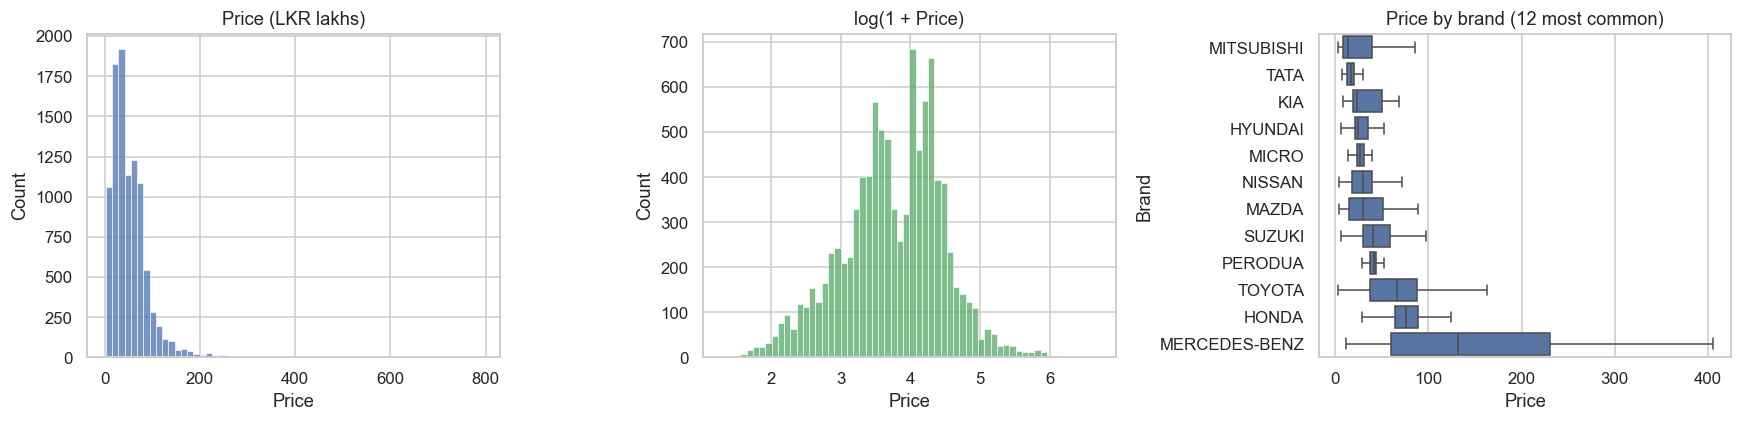

Skewness of Price: 3.46 | skewness of log(1+Price): -0.22


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(raw.Price, bins=60, ax=ax[0], color="#4c72b0"); ax[0].set_title("Price (LKR lakhs)")
sns.histplot(np.log1p(raw.Price), bins=60, ax=ax[1], color="#55a868"); ax[1].set_title("log(1 + Price)")
top = raw.Brand.value_counts().head(12).index
order = raw[raw.Brand.isin(top)].groupby("Brand").Price.median().sort_values().index
sns.boxplot(data=raw[raw.Brand.isin(top)], y="Brand", x="Price", order=order, ax=ax[2], showfliers=False)
ax[2].set_title("Price by brand (12 most common)")
plt.tight_layout(); plt.show()
print("Skewness of Price:", round(raw.Price.skew(), 2), "| skewness of log(1+Price):", round(np.log1p(raw.Price).skew(), 2))

`Price` is strongly right-skewed (skewness 3.46). The middle half of the cars cost Rs. 2.6 to 7.0 million, but a few go up to Rs. 79 million. After `log(1 + price)` the skewness is -0.22, almost symmetric, so I model the **log price**. The error is then relative, a 10% miss counts the same on a cheap Alto and on a Mercedes.

Brand matters. Among the 12 most common brands, Mercedes-Benz, Honda and Toyota have the highest medians. Honda and Toyota hold their value well here, and Mercedes-Benz also has the widest spread. Mitsubishi, Tata and Kia are the cheapest.


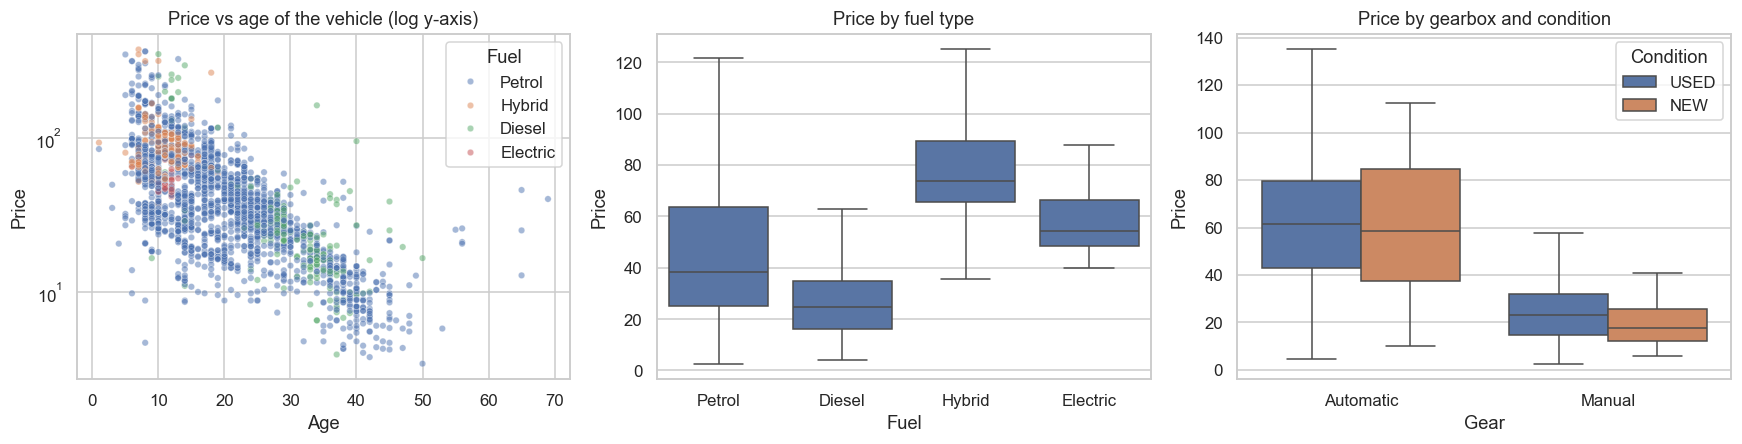

In [8]:
raw["Age"] = 2025 - raw.YOM
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
sns.scatterplot(data=raw.sample(3000, random_state=SEED), x="Age", y="Price", hue="Fuel", alpha=.5, s=18, ax=ax[0])
ax[0].set_yscale("log"); ax[0].set_title("Price vs age of the vehicle (log y-axis)")
sns.boxplot(data=raw, x="Fuel", y="Price", ax=ax[1], showfliers=False); ax[1].set_title("Price by fuel type")
sns.boxplot(data=raw, x="Gear", y="Price", hue="Condition", ax=ax[2], showfliers=False); ax[2].set_title("Price by gearbox and condition")
plt.tight_layout(); plt.show()

On a log axis, price falls almost in a straight line with age. Each extra year multiplies the price by about the same factor, so depreciation is multiplicative. That is another reason to use a log target. The spread also gets wider for old cars, vehicles aged 30+ run from about Rs. 0.6 M to Rs. 3.0 M, which age alone cannot explain.

Hybrid cars have the highest median price, then electric, petrol, and diesel. Automatic cars cost much more than manual ones.

`Condition = NEW` is only 94 of 9,788 rows (under 1%), so I do not expect it to help much. I check this later with permutation importance.


### Mileage is not a real measurement
`Mileage_km` has a correlation of exactly **-1.00** with year of manufacture. That is too clean for real adverts, so I checked it directly.


Rows where Mileage_km == 11,000 x age : 9788 of 9788
Different mileage values per manufacturing year (max): 1


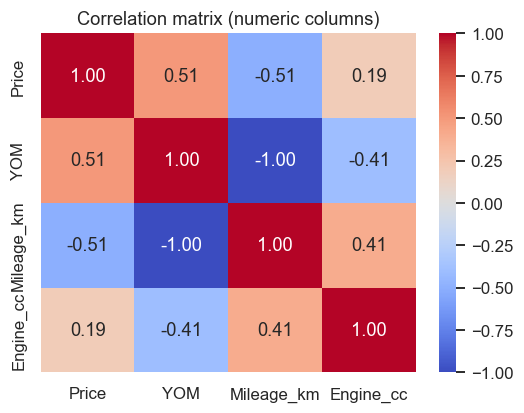

In [9]:
print("Rows where Mileage_km == 11,000 x age :", (raw.Mileage_km == 11000 * raw.Age).sum(), "of", len(raw))
print("Different mileage values per manufacturing year (max):", raw.groupby("YOM").Mileage_km.nunique().max())
plt.figure(figsize=(5.5, 4))
sns.heatmap(raw[["Price", "YOM", "Mileage_km", "Engine_cc"]].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation matrix (numeric columns)"); plt.show()

`Mileage_km` equals exactly `11,000 x (2025 - year)` in **all 9,788 rows**, and each year has only one mileage value. It was not taken from the adverts. It looks like a default of 11,000 km per year.

It adds nothing beyond the car's age, so I drop it. Keeping a perfect copy of age would only hurt Ridge and the ANN.

This is a real limit of the data. Mileage is one of the main things that sets a used-car price, and the models cannot tell a hard-driven car from a lightly used one.


In [10]:
# other sanity checks
dups = raw.drop(columns=["Unnamed: 0", "Date"]).duplicated().sum()
print("Repeated adverts (identical in everything except the posting date):", dups)
print("\nCars with engine capacity below 800 cc that are NOT Perodua/Micro/Suzuki/Daihatsu kei-type:")
odd = raw[(raw.Engine_cc < 800) & (~raw.Brand.isin(["PERODUA", "MICRO", "SUZUKI", "DAIHATSU", "MITSUBISHI"]))]
print(len(odd), "rows, e.g.")
odd[["Brand", "Model", "YOM", "Engine_cc", "Fuel", "Price"]].head(6)

Repeated adverts (identical in everything except the posting date): 252

Cars with engine capacity below 800 cc that are NOT Perodua/Micro/Suzuki/Daihatsu kei-type:
151 rows, e.g.


,Brand,Model,YOM,Engine_cc,Fuel,Price
149,BMW,I3 REX,2016,650.0,Hybrid,167.0000
150,BMW,I3 REX,2016,650.0,Hybrid,167.0000
163,CHERY,QQ,2011,798.0,Petrol,12.0375
171,CHERY,QQ,2006,798.0,Petrol,11.3000
186,CHERY,QQ,2008,798.0,Petrol,18.3750
193,CHERY,QQ,2009,798.0,Petrol,12.4000


* **252 repeated adverts** (the same car posted again on another date) are removed in the next section, so a copy cannot sit in both train and test.
* Some engine sizes look wrong, for example a Lexus 600hL listed as 600 cc. I cannot check each advert, so I keep them. Trees cope with a few outliers, and they show up later as a spike at 600 cc in the partial dependence plot.


## 3. Preprocessing and evaluation design

### Cleaning and features
* Drop the index column `Unnamed: 0`.
* Drop repeated adverts. If I leave them, one copy can land in train and the other in test, and the score looks better than it is.
* Drop `Mileage_km` (it is just `11,000 x age`) and `Date` (the day the advert was posted is not a property of the car).
* New features, inside the pipeline (`ensemble_utils.add_features`), `Age = 2025 - YOM`, equipment flags as 0/1, and `EquipScore` = how many comfort features the car has.
* Categories are one-hot encoded. Levels with fewer than 10 adverts are grouped as "infrequent", so 1,555 models do not blow up the feature space. Unseen levels at prediction time are handled.
* Scaling is only for the models that need it (Ridge, SVR, ANN). Trees are not affected by scale.
* There are no missing values, but I keep `SimpleImputer` in the pipeline so a blank input in the dashboard does not crash.
* **Target,** `log(1 + Price)`, then convert back. Prices run from about Rs. 0.3 M to Rs. 79 M and are right-skewed.
* **SMOTE does not apply.** This is regression, so there are no classes to balance.


In [11]:
df = raw.drop(columns=["Unnamed: 0"]).copy()
n0 = len(df)
df = df.drop_duplicates(subset=[c for c in df.columns if c != "Date"]).reset_index(drop=True)
print(f"Rows: {n0} -> {len(df)} after removing {n0 - len(df)} repeated adverts")
df = df.drop(columns=["Mileage_km", "Date", "Age"])
if QUICK:
    df = df.sample(1500, random_state=SEED).reset_index(drop=True)

X = df[eu.RAW_COLS]
y = df["Price"]
price_bins = pd.qcut(y, 5, labels=False)              # stratify the split so every price range is in both sets
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=price_bins)
print("Train:", Xtr.shape, " Test:", Xte.shape)

# same rows, log target, for the quick fits that skip the full pipeline
fe_pre = Pipeline([("fe", FunctionTransformer(eu.add_features)), ("pre", eu.make_preprocessor(scale=False))]).fit(Xtr)
Xtr_t, Xte_t = fe_pre.transform(Xtr), fe_pre.transform(Xte)
ytr_log, yte_log = np.log1p(ytr.values), np.log1p(yte.values)
print("Features after preprocessing:", Xtr_t.shape[1])

Rows: 9788 -> 9536 after removing 252 repeated adverts
Train: (7628, 13)  Test: (1908, 13)


Features after preprocessing: 280


### Metrics
This is regression, so Recall and F1 do not apply.

| Metric | Why I use it |
|---|---|
| **RMSLE** (RMSE of `log(1+price)`) | **Main metric for tuning.** Prices cover a huge range, and a buyer cares about the *relative* error. Being Rs. 1 M off a Rs. 2 M car is much worse than being Rs. 1 M off a Rs. 50 M car. |
| **MAE** (lakhs) | The typical error in rupees. Easy to explain. |
| **RMSE** (lakhs) | Punishes large misses. Those are mostly the expensive cars. |
| **R2** | How much of the price variation the model explains. |
| **MAPE** | Average percentage error. The easiest number to explain. |

All models use the **same 80/20 split** (stratified by price band) and the **same pipeline**. Hyperparameters come only from cross-validation on the training set. The test set is used once per final model.


In [12]:
def rmsle(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred))))

rmsle_scorer = make_scorer(rmsle, greater_is_better=False)
def rmse_arr(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

# bookkeeping used for the final comparison
final_models, test_pred, family, fit_secs, tuning_log = {}, {}, {}, {}, []

def register(name, model, fam, secs):
    final_models[name] = model
    family[name] = fam
    fit_secs[name] = secs
    test_pred[name] = model.predict(Xte)
    m = eu.evaluate(yte, test_pred[name])
    print(f"{name:28s} MAE={m['MAE']:.2f}  RMSE={m['RMSE']:.2f}  R2={m['R2']:.3f}  MAPE={m['MAPE_%']:.1f}%  RMSLE={m['RMSLE']:.3f}  ({secs:.0f}s)")

def tune(name, estimator, grid, fam, scale=False, cv=3):
    gs = GridSearchCV(eu.make_pipe(estimator, scale=scale), grid, cv=cv, scoring=rmsle_scorer, n_jobs=1, refit=True)
    gs.fit(Xtr, ytr)
    best = {k.replace("regressor__model__", ""): v for k, v in gs.best_params_.items()}
    tuning_log.append({"Model": name, "Best params": str(best), "CV RMSLE": -gs.best_score_, "Grid size": len(gs.cv_results_["params"])})
    print(f"[{name}] best params {best} | CV RMSLE = {-gs.best_score_:.4f}")
    register(name, gs.best_estimator_, fam, gs.refit_time_ + 0.0)
    return gs

## 4. Baselines and the bias-variance picture

Before the ensembles I need baselines. Ridge shows what a linear model can do. A single decision tree is the base learner of Random Forest, so the gap between one tree and the forest is the effect of bagging.

I use `validation_curve` on tree depth to show the bias-variance trade-off, shallow trees underfit (high bias), very deep trees memorise the training set (high variance).


Ridge (linear baseline)      MAE=7.26  RMSE=17.12  R2=0.837  MAPE=17.0%  RMSLE=0.252  (0s)


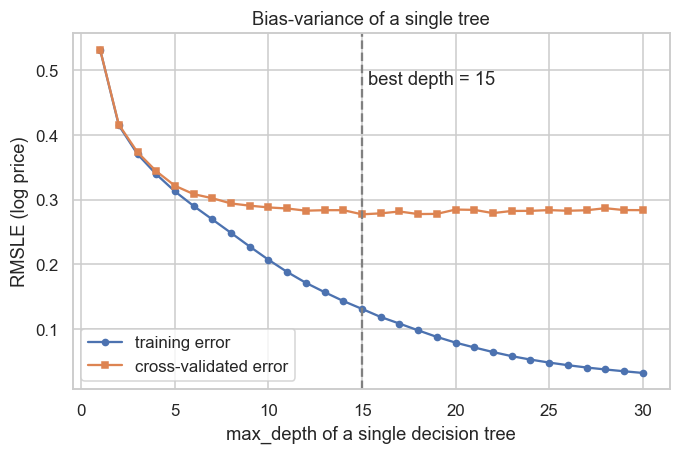

Decision Tree                MAE=7.64  RMSE=19.61  R2=0.786  MAPE=18.1%  RMSLE=0.277  (0s)


In [13]:
t = time.time()
ridge = eu.make_pipe(Ridge(alpha=1.0), scale=True).fit(Xtr, ytr)
register("Ridge (linear baseline)", ridge, "Baseline", time.time() - t)

depths = list(range(1, 31))
tr_s, va_s = validation_curve(DecisionTreeRegressor(random_state=SEED), Xtr_t, ytr_log, param_name="max_depth",
                              param_range=depths, scoring="neg_root_mean_squared_error", cv=5, n_jobs=-1)
tr_err, va_err = -tr_s.mean(1), -va_s.mean(1)
best_depth = depths[int(np.argmin(va_err))]

plt.figure(figsize=(7, 4.2))
plt.plot(depths, tr_err, "o-", label="training error", ms=4)
plt.plot(depths, va_err, "s-", label="cross-validated error", ms=4)
plt.axvline(best_depth, ls="--", c="grey"); plt.text(best_depth + .3, va_err.max() * .9, f"best depth = {best_depth}")
plt.xlabel("max_depth of a single decision tree"); plt.ylabel("RMSLE (log price)")
plt.title("Bias-variance of a single tree"); plt.legend(); plt.show()

t = time.time()
tree = eu.make_pipe(DecisionTreeRegressor(max_depth=best_depth, random_state=SEED)).fit(Xtr, ytr)
register("Decision Tree", tree, "Baseline", time.time() - t)

* Depth 1 to 5, both curves are high and close together. The tree is too simple (**high bias, underfitting**).
* Past depth about 10, the training error keeps falling towards 0 while the cross-validated error stays near 0.28. That gap is the **variance** (overfitting). The tree is memorising the training adverts.
* One tree only reaches R2 = 0.786, which is worse than ridge (0.837). A single unstable tree is a weak learner. Bagging is meant to fix that.


## 5. Bagging and Random Forest

Bagging means **b**ootstrap **agg**regat**ing**, train many trees on bootstrap samples (drawn with replacement) and average them.
The variance of that average is

$$\text{Var}(\bar f) = \rho\,\sigma^2 + \frac{1-\rho}{B}\sigma^2$$

There are two ways to bring this down, more trees (`B`), and less correlation (`rho`) between the trees. Random Forest does the second one by letting each split see only a random subset of the features (`max_features`). I check both below, and I also use the **out-of-bag (OOB)** rows as a free validation set.


In [14]:
# (a) bagging with full trees, every tree sees all the features
t = time.time()
bag = eu.make_pipe(BaggingRegressor(DecisionTreeRegressor(), n_estimators=200, bootstrap=True, oob_score=True,
                                    n_jobs=-1, random_state=SEED)).fit(Xtr, ytr)
register("Bagging (Decision Trees)", bag, "Bagging", time.time() - t)
print("OOB R2 of the bagged trees (log scale):", round(bag.regressor_.named_steps["model"].oob_score_, 4))

Bagging (Decision Trees)     MAE=5.49  RMSE=15.17  R2=0.872  MAPE=13.2%  RMSLE=0.217  (12s)
OOB R2 of the bagged trees (log scale): 0.9095


Bagging 200 full decision trees lifts R2 from 0.786 (one tree) to 0.872, and RMSLE falls from 0.277 to 0.217. Same learner, only averaging.
The OOB score costs nothing extra, each training row is predicted only by the trees that did not see it.


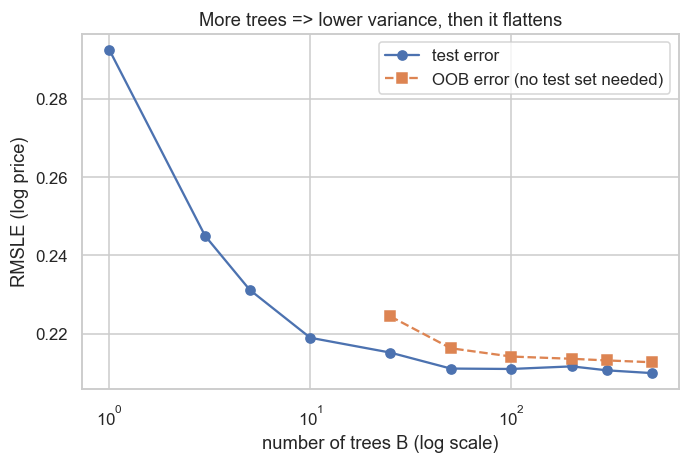

,B,OOB,Test
0,1,NaN,0.2925
1,3,NaN,0.2449
2,5,NaN,0.2312
3,10,NaN,0.2189
4,25,0.2244,0.2152
5,50,0.2163,0.2111
6,100,0.2142,0.2110
7,200,0.2136,0.2116
8,300,0.2132,0.2106
9,500,0.2127,0.2099


In [15]:
# (b) number of trees B, OOB error against test error
rf_sweep = RandomForestRegressor(max_features=0.33, oob_score=True, warm_start=True, n_jobs=-1, random_state=SEED)
rows = []
for B in [1, 3, 5, 10, 25, 50, 100, 200, 300, 500]:
    rf_sweep.set_params(n_estimators=B).fit(Xtr_t, ytr_log)
    rows.append({"B": B,
                 "OOB": rmse_arr(ytr_log, rf_sweep.oob_prediction_) if B >= 25 else np.nan,
                 "Test": rmse_arr(yte_log, rf_sweep.predict(Xte_t))})
oob_df = pd.DataFrame(rows)
oob_df.to_csv("results/bagging_oob_vs_trees.csv", index=False)

plt.figure(figsize=(7, 4.2))
plt.plot(oob_df.B, oob_df.Test, "o-", label="test error")
plt.plot(oob_df.B, oob_df.OOB, "s--", label="OOB error (no test set needed)")
plt.xscale("log"); plt.xlabel("number of trees B (log scale)"); plt.ylabel("RMSLE (log price)")
plt.title("More trees => lower variance, then it flattens"); plt.legend(); plt.show()
oob_df.round(4)

* Test RMSLE falls from 0.292 (1 tree) to 0.219 (10 trees) and about 0.211 at 100 trees, then it is flat (0.210 at 500). That is the `(1 - rho) / B` term shrinking towards zero. What is left is the `rho x sigma^2` floor, which more trees cannot remove.
* The **OOB error tracks the test error** (0.213 vs 0.210 at 500 trees), so the OOB rows can stand in for a separate validation set. It is slightly pessimistic, because each row is predicted by only the ~37% of trees that did not see it.
* About 200 trees is enough. After that the error stays about the same, and the model only gets bigger and slower.


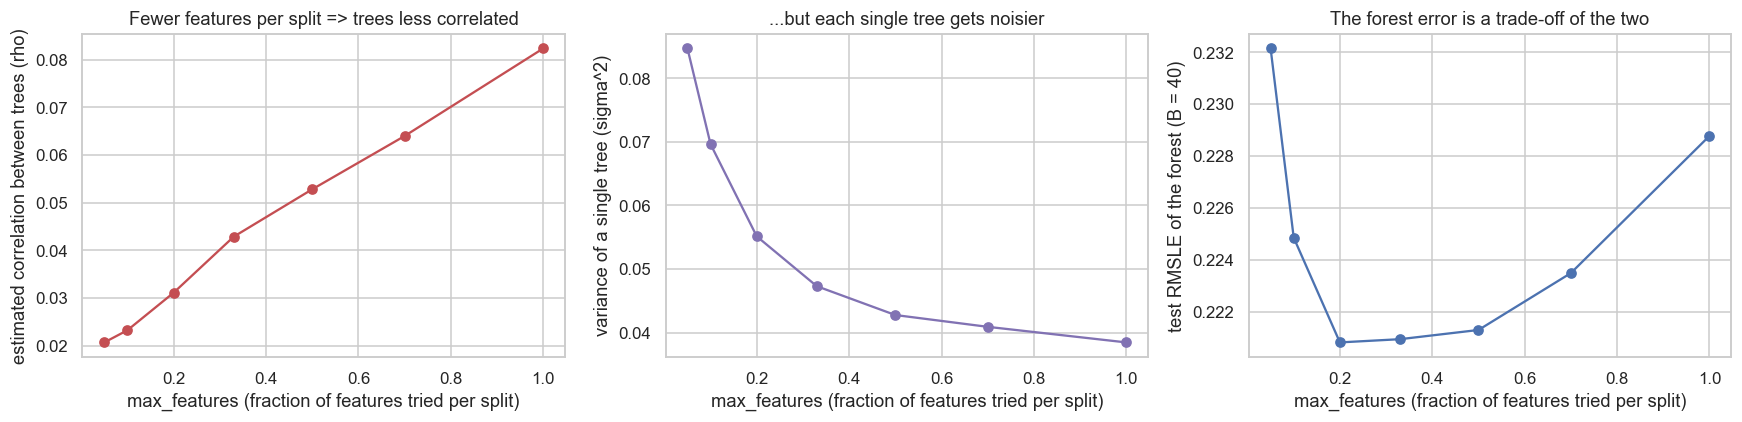

,max_features,tree variance s2,rho,Test RMSLE
0,1.00,0.0384,0.0823,0.2288
1,0.70,0.0409,0.0640,0.2235
2,0.50,0.0428,0.0528,0.2213
3,0.33,0.0473,0.0429,0.2209
4,0.20,0.0551,0.0311,0.2208
5,0.10,0.0696,0.0233,0.2248
6,0.05,0.0847,0.0207,0.2321


In [16]:
# (c) tree correlation vs max_features.
# rho is how alike two trees in the same forest are when the training set changes.
# I train forests on K different 70% subsamples, then rho = V_between / (V_between + s2).
# s2 is the spread among trees in one forest. V_between is the part they all share.
Xte32 = Xte_t.astype(np.float32)
def estimate_rho(max_features, B=40, K=8, frac=0.7):
    rng = np.random.default_rng(0)
    means, s2s, errs = [], [], []
    for k in range(K):
        idx = rng.choice(len(Xtr_t), int(frac * len(Xtr_t)), replace=False)       # a different training set each time
        rf = RandomForestRegressor(n_estimators=B, max_features=max_features, n_jobs=-1, random_state=100 + k).fit(Xtr_t[idx], ytr_log[idx])
        P = np.array([tr.predict(Xte32) for tr in rf.estimators_])              # (B, n_test): every tree's prediction
        means.append(P.mean(0)); s2s.append(P.var(0, ddof=1)); errs.append(rmse_arr(yte_log, P.mean(0)))
    V, s2 = np.var(means, axis=0, ddof=1).mean(), np.mean(s2s, axis=0).mean()
    V_between = max(V - s2 / B, 0)
    return {"max_features": max_features, "tree variance s2": s2, "rho": V_between / (V_between + s2), "Test RMSLE": np.mean(errs)}

rho_df = pd.DataFrame([estimate_rho(mf) for mf in [1.0, 0.7, 0.5, 0.33, 0.2, 0.1, 0.05]])
rho_df.to_csv("results/bagging_rho_vs_max_features.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(rho_df.max_features, rho_df.rho, "o-", c="#c44e52"); ax[0].set_ylabel("estimated correlation between trees (rho)")
ax[0].set_title("Fewer features per split => trees less correlated")
ax[1].plot(rho_df.max_features, rho_df["tree variance s2"], "o-", c="#8172b3"); ax[1].set_ylabel("variance of a single tree (sigma^2)")
ax[1].set_title("...but each single tree gets noisier")
ax[2].plot(rho_df.max_features, rho_df["Test RMSLE"], "o-"); ax[2].set_ylabel("test RMSLE of the forest (B = 40)")
ax[2].set_title("The forest error is a trade-off of the two")
for a in ax: a.set_xlabel("max_features (fraction of features tried per split)")
plt.tight_layout(); plt.show()
rho_df.round(4)

This checks the correlation between the trees, the second term in the variance formula.
* When every split can see all the features (`max_features = 1.0`), the trees are the most alike, estimated rho = 0.082. They all pick the same strong features first (year, gearbox, brand). One strong predictor makes the trees look alike, because every tree puts that feature near the root.
* Limiting each split to a random 5-20% of the features drops rho to 0.021-0.031, but each tree gets noisier (sigma^2 rises from 0.038 to 0.085), because it is often forced to split on a weak column.
* The two effects work against each other, so the test error is **U-shaped**. It is best around `max_features` 0.2-0.5 (RMSLE 0.221) and worse at both ends (0.229 at 1.0, 0.232 at 0.05). That is why Random Forest is preferred to plain bagging.
* My rho estimate uses overlapping 70% subsamples of one dataset, so the numbers themselves are small. The trend is what matters. These forests also have only 40 trees on 70% of the data, which is why their errors are higher than the tuned forest.


In [17]:
# (d) tune the Random Forest with GridSearchCV
rf_grid = {"regressor__model__max_features": [0.2, 0.33, 0.5],
           "regressor__model__min_samples_leaf": [1, 2, 4]}
rf_gs = tune("Random Forest", RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED), rf_grid, "Bagging")

[Random Forest] best params {'max_features': 0.33, 'min_samples_leaf': 1} | CV RMSLE = 0.2228
Random Forest                MAE=5.40  RMSE=14.71  R2=0.879  MAPE=12.8%  RMSLE=0.212  (4s)


`GridSearchCV` picked `max_features = 0.33` and `min_samples_leaf = 1` (CV RMSLE 0.2228), which matches the experiment above. On the test set the tuned forest reaches RMSLE 0.212 and R2 0.879, a bit better than plain bagging (0.217 / 0.872). The paired bootstrap later shows that small gap is not significant. Both are far better than one tree. On this data, most of the gain comes from bagging itself. Feature subsampling adds a little on top.


## 6. Boosting, XGBoost, LightGBM, CatBoost

Bagging cuts **variance** by averaging deep trees. **Boosting** goes after **bias**, the trees are built one after another, and each new shallow tree is fitted to the errors the ensemble still makes.

AdaBoost does the same job by raising the weight of the examples that were predicted badly. XGBoost, LightGBM and CatBoost use gradient boosting instead, so each new tree is fitted directly to the remaining errors (residuals).

They differ mainly in how they grow trees and how they treat categories,

* **XGBoost**, level-wise growth, second-order gradients, L1/L2 regularisation.
* **LightGBM**, leaf-wise growth with histogram binning, so it is faster, but it can overfit small data if `num_leaves` is large.
* **CatBoost**, symmetric trees and ordered boosting, meant to reduce target leakage. It can also take categorical columns directly.

I tune each one with `GridSearchCV` (3-fold, RMSLE).


In [18]:
xgb_gs = tune("XGBoost", XGBRegressor(learning_rate=0.05, subsample=0.8, colsample_bytree=0.6, tree_method="hist",
                                       n_jobs=-1, random_state=SEED),
              {"regressor__model__max_depth": [4, 6, 8], "regressor__model__n_estimators": [400, 800]}, "Boosting")

[XGBoost] best params {'max_depth': 8, 'n_estimators': 400} | CV RMSLE = 0.2184
XGBoost                      MAE=5.64  RMSE=14.06  R2=0.890  MAPE=12.7%  RMSLE=0.200  (5s)


In [19]:
lgb_gs = tune("LightGBM", LGBMRegressor(learning_rate=0.05, subsample=0.8, subsample_freq=1, colsample_bytree=0.6,
                                         n_jobs=-1, random_state=SEED, verbose=-1),
              {"regressor__model__num_leaves": [15, 31, 63], "regressor__model__n_estimators": [400, 800]}, "Boosting")

[LightGBM] best params {'n_estimators': 400, 'num_leaves': 63} | CV RMSLE = 0.2269
LightGBM                     MAE=5.87  RMSE=14.38  R2=0.885  MAPE=13.7%  RMSLE=0.211  (5s)


In [20]:
cat_gs = tune("CatBoost", CatBoostRegressor(iterations=800, learning_rate=0.05, verbose=0, random_seed=SEED, thread_count=-1),
              {"regressor__model__depth": [4, 6, 8], "regressor__model__l2_leaf_reg": [3, 10]}, "Boosting")

[CatBoost] best params {'depth': 8, 'l2_leaf_reg': 3} | CV RMSLE = 0.2213
CatBoost                     MAE=5.99  RMSE=14.45  R2=0.884  MAPE=13.5%  RMSLE=0.205  (14s)


In [21]:
# CatBoost on the raw category columns, instead of one-hot
cat_best = cat_gs.best_params_
t = time.time()
cat_native = eu.make_native_catboost_pipe(iterations=800, depth=cat_best["regressor__model__depth"],
                                          l2_leaf_reg=cat_best["regressor__model__l2_leaf_reg"]).fit(Xtr, ytr)
register("CatBoost (native categoricals)", cat_native, "Boosting", time.time() - t)

CatBoost (native categoricals) MAE=6.28  RMSE=14.74  R2=0.879  MAPE=14.0%  RMSLE=0.210  (82s)


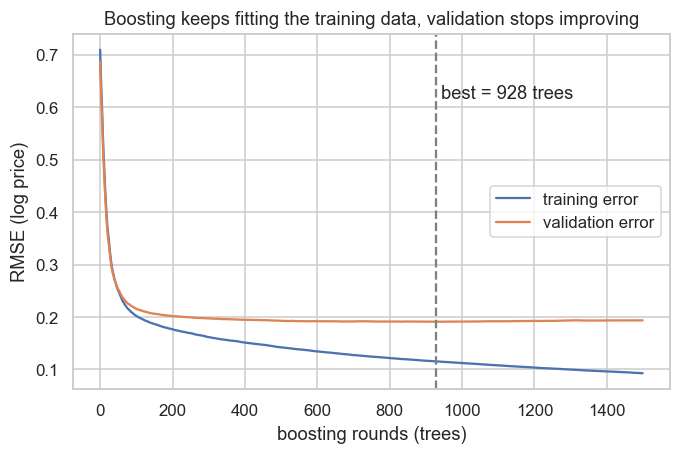

In [22]:
# XGBoost train vs validation error as trees are added (validation = 15% of the training data)
Xa, Xv, ya, yv = train_test_split(Xtr_t, ytr_log, test_size=0.15, random_state=SEED)
xgb_curve = XGBRegressor(n_estimators=1500, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.6,
                         eval_metric="rmse", tree_method="hist", n_jobs=-1, random_state=SEED)
xgb_curve.fit(Xa, ya, eval_set=[(Xa, ya), (Xv, yv)], verbose=False)
ev = xgb_curve.evals_result()
plt.figure(figsize=(7, 4.2))
plt.plot(ev["validation_0"]["rmse"], label="training error")
plt.plot(ev["validation_1"]["rmse"], label="validation error")
best_it = int(np.argmin(ev["validation_1"]["rmse"]))
plt.axvline(best_it, ls="--", c="grey"); plt.text(best_it + 15, max(ev["validation_1"]["rmse"]) * .9, f"best = {best_it} trees")
plt.xlabel("boosting rounds (trees)"); plt.ylabel("RMSE (log price)"); plt.title("Boosting keeps fitting the training data, validation stops improving")
plt.legend(); plt.show()

The training error keeps falling for all 1,500 rounds, but the validation error flattens after a few hundred. A small learning rate slows the overfitting, but boosting still overfits if I just keep adding trees. I tune depth, number of trees and regularisation with cross-validation instead.

**Tuned results**

| Model | Best parameters (3-fold CV) | CV RMSLE | Test RMSLE | Test R2 | Fit time |
|---|---|---|---|---|---|
| XGBoost | max_depth 8, n_estimators 400 | 0.2184 | 0.200 | 0.890 | 5 s |
| LightGBM | n_estimators 400, num_leaves 63 | 0.2269 | 0.211 | 0.885 | 5 s |
| CatBoost (one-hot) | depth 8, l2_leaf_reg 3 | 0.2213 | 0.205 | 0.884 | 14 s |
| CatBoost (native categoricals) | same depth / l2 | - | 0.210 | 0.879 | 82 s |

* **XGBoost** is the best single boosted model. It beats the tuned Random Forest (RMSLE 0.200 vs 0.212).
* **LightGBM** is the fastest and a bit behind. With 63 leaves it chases rare brand/model combinations on about 7,600 training rows.
* **CatBoost** with one-hot input is close. Its native categorical mode was slower (about 6x) and not better. My guess is that with 1,555 models, many seen only once or twice, the ordered target statistics are noisy, while pooling rare one-hot levels acts as regularisation. I did not test that guess further.


## 7. Stacking

Stacking trains a meta-learner on the *out-of-fold* predictions of the base models, so it can learn how much to trust each one. It only helps if the base models make *different* mistakes. Besides the tree ensembles I add two non-tree models, an **SVR** and an **ANN** (MLP). I tune those first.


In [23]:
svr_gs = tune("SVR (RBF kernel)", SVR(epsilon=0.05), {"regressor__model__C": [1, 3, 10], "regressor__model__gamma": ["scale", 0.01]},
              "Other", scale=True)

[SVR (RBF kernel)] best params {'C': 3, 'gamma': 'scale'} | CV RMSLE = 0.2250


SVR (RBF kernel)             MAE=6.03  RMSE=15.66  R2=0.863  MAPE=13.6%  RMSLE=0.211  (8s)


In [24]:
ann_gs = tune("ANN (MLP)", MLPRegressor(early_stopping=True, validation_fraction=0.15, n_iter_no_change=15, max_iter=500, random_state=SEED),
              {"regressor__model__hidden_layer_sizes": [(64,), (64, 32), (128, 64)],
               "regressor__model__alpha": [1e-3, 1e-2, 1e-1]}, "Other", scale=True)

[ANN (MLP)] best params {'alpha': 0.1, 'hidden_layer_sizes': (64, 32)} | CV RMSLE = 0.2313
ANN (MLP)                    MAE=6.24  RMSE=14.43  R2=0.884  MAPE=14.1%  RMSLE=0.214  (8s)


In [25]:
def raw_est(gs):                      # the tuned (unfitted) estimator inside a GridSearchCV pipeline
    return clone(gs.best_estimator_.regressor_.named_steps["model"])

rf_est = raw_est(rf_gs).set_params(oob_score=False)
base_models = [("rf", rf_est), ("xgb", raw_est(xgb_gs)), ("cat", raw_est(cat_gs)), ("svr", raw_est(svr_gs)), ("ann", raw_est(ann_gs))]

t = time.time()
stack = eu.make_pipe(StackingRegressor(estimators=base_models, final_estimator=RidgeCV(alphas=np.logspace(-3, 2, 20)),
                                       cv=5, n_jobs=1), scale=True).fit(Xtr, ytr)
register("Stacking (RF+XGB+Cat+SVR+ANN)", stack, "Stacking", time.time() - t)

st = stack.regressor_.named_steps["model"]
print("\nMeta-learner (Ridge) weights on the log-price predictions of each base model:")
print(pd.Series(st.final_estimator_.coef_, index=[n for n, _ in base_models]).round(3).to_string(), "| intercept", round(st.final_estimator_.intercept_, 3))

Stacking (RF+XGB+Cat+SVR+ANN) MAE=5.39  RMSE=14.00  R2=0.891  MAPE=12.3%  RMSLE=0.198  (225s)

Meta-learner (Ridge) weights on the log-price predictions of each base model:
rf     0.158
xgb    0.332
cat    0.205
svr    0.226
ann    0.092 | intercept -0.048


The meta-learner puts the most weight on XGBoost (0.33), then SVR (0.23), CatBoost (0.20), RF (0.16) and the ANN (0.09). The weights are all positive and sum to about 1.01, so this is basically a weighted average. SVR and the ANN together still get 0.32 even though each one is weaker on its own, which means they add something the trees do not.


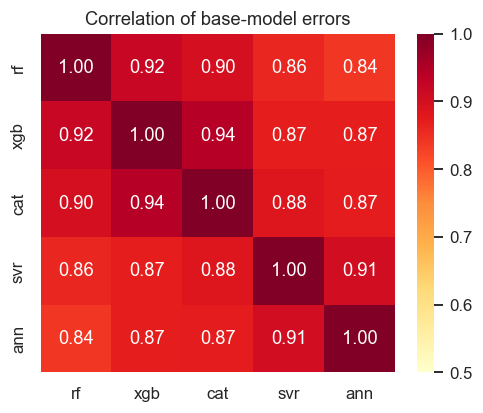

Simple average of the 5 base models:  RMSE = 14.05  MAE = 5.43  R2 = 0.890
   base model alone rf  : RMSE = 14.70
   base model alone xgb : RMSE = 14.06
   base model alone cat : RMSE = 14.45
   base model alone svr : RMSE = 15.66
   base model alone ann : RMSE = 14.43


In [26]:
# Do the base models miss different cars? Correlation of test errors, plus a simple average
Xte_stack = stack.regressor_[:-1].transform(Xte)
base_pred = pd.DataFrame({n: m.predict(Xte_stack) for n, m in zip([n for n, _ in base_models], st.estimators_)})
errs = base_pred.sub(yte_log, axis=0)
plt.figure(figsize=(5.2, 4)); sns.heatmap(errs.corr(), annot=True, cmap="YlOrRd", vmin=.5, vmax=1, fmt=".2f")
plt.title("Correlation of base-model errors"); plt.show()

avg_pred = np.expm1(base_pred.mean(axis=1))
m_avg = eu.evaluate(yte, avg_pred)
print("Simple average of the 5 base models:  RMSE = %.2f  MAE = %.2f  R2 = %.3f" % (m_avg["RMSE"], m_avg["MAE"], m_avg["R2"]))
for n in base_pred:
    print(f"   base model alone {n:4s}: RMSE = {eu.evaluate(yte, np.expm1(base_pred[n]))['RMSE']:.2f}")

* The base-model errors are highly correlated (0.84 to 0.94). RF, XGBoost and CatBoost are the most alike (0.90-0.94). SVR and the ANN are close to each other (0.91). A tree model vs SVR/ANN is a bit lower (0.84-0.88), and that is where the useful difference is.
* Because they mostly miss the same cars, stacking does not have much room to improve. It reaches RMSLE 0.198 and RMSE 14.00, only slightly better than XGBoost alone (0.200 / 14.06).
* A simple average of the five base models already gets RMSE 14.05, almost the same as the trained meta-learner. The gain comes from using different models.
* Stacking took 225 s to train, against 5 s for XGBoost, and the saved model is about 32 MB.


## 8. Hybrid, Random Forest + ANN

For this dataset I combine a **Random Forest** with an **ANN**. I try three ways (all in `RFANNHybrid`) and pick the winner by **cross-validation on the training set**, not by the test score,

1. **Blend.** The forest and a small bag of ANNs are trained separately, then averaged.
2. **Residual correction.** The ANN is trained on the forest's out-of-bag residuals and added on top. Those predictions are safe to learn from, because those trees never saw that row.
3. **RF-feature ANN.** The forest's OOB prediction is given to the ANN as one extra input.


In [27]:
ann_hidden = ann_gs.best_params_["regressor__model__hidden_layer_sizes"]
ann_alpha = ann_gs.best_params_["regressor__model__alpha"]
rf_p = {k.replace("regressor__model__", ""): v for k, v in rf_gs.best_params_.items()}
print("ANN setting from the grid search:", ann_hidden, ann_alpha, "| RF setting:", rf_p)

variants = {
    "Hybrid RF+ANN (blend)":       dict(mode="blend", rf_weight=0.5, n_ann=3),
    "Hybrid RF+ANN (residual)":    dict(mode="residual", ann_weight=1.0, n_ann=1),
    "Hybrid RF+ANN (residual x0.3)": dict(mode="residual", ann_weight=0.3, n_ann=1),
    "Hybrid RF+ANN (RF-feature)":  dict(mode="rf_feature", n_ann=3),
}
common = dict(n_estimators=200, hidden_layer_sizes=ann_hidden, alpha=ann_alpha, **rf_p)
cv_scores = {}
for name, kw in variants.items():
    s = cross_val_score(eu.make_hybrid_pipe(**common, **kw), Xtr, ytr, cv=3, scoring=rmsle_scorer, n_jobs=1)
    cv_scores[name] = -s.mean()
    print(f"{name:32s} CV RMSLE = {-s.mean():.4f} (+/- {s.std():.4f})")
best_hybrid_name = min(cv_scores, key=cv_scores.get)
print("\nBest hybrid by cross-validation:", best_hybrid_name)

ANN setting from the grid search: (64, 32) 0.1 | RF setting: {'max_features': 0.33, 'min_samples_leaf': 1}


Hybrid RF+ANN (blend)            CV RMSLE = 0.2148 (+/- 0.0027)


Hybrid RF+ANN (residual)         CV RMSLE = 0.2245 (+/- 0.0024)


Hybrid RF+ANN (residual x0.3)    CV RMSLE = 0.2219 (+/- 0.0014)


Hybrid RF+ANN (RF-feature)       CV RMSLE = 0.2170 (+/- 0.0054)

Best hybrid by cross-validation: Hybrid RF+ANN (blend)


In [28]:
for name, kw in variants.items():
    t = time.time()
    h = eu.make_hybrid_pipe(**common, **kw).fit(Xtr, ytr)
    register(name, h, "Hybrid", time.time() - t)
tuning_log.append({"Model": "Hybrid RF+ANN (CV-selected: " + best_hybrid_name + ")", "Best params": str(variants[best_hybrid_name]),
                   "CV RMSLE": cv_scores[best_hybrid_name], "Grid size": len(variants)})

Hybrid RF+ANN (blend)        MAE=5.39  RMSE=14.05  R2=0.890  MAPE=12.6%  RMSLE=0.203  (27s)


Hybrid RF+ANN (residual)     MAE=5.54  RMSE=14.29  R2=0.886  MAPE=13.0%  RMSLE=0.210  (7s)


Hybrid RF+ANN (residual x0.3) MAE=5.39  RMSE=14.53  R2=0.882  MAPE=12.8%  RMSLE=0.211  (7s)


Hybrid RF+ANN (RF-feature)   MAE=5.42  RMSE=13.53  R2=0.898  MAPE=12.8%  RMSLE=0.202  (22s)


**The three hybrid designs**

| Design | CV RMSLE (train only) | Test RMSLE | Test R2 |
|---|---|---|---|
| Blend (RF + 3 ANNs, 50/50) | 0.2148 | 0.203 | 0.890 |
| Residual correction (ANN weight 1.0) | 0.2245 | 0.210 | 0.886 |
| Residual correction (ANN weight 0.3) | 0.2219 | 0.211 | 0.882 |
| RF-feature ANN | 0.2170 | 0.202 | 0.898 |
| Random Forest alone | 0.2228 | 0.212 | 0.879 |
| ANN alone | 0.2313 | 0.214 | 0.884 |

* **Blend** wins cross-validation, so that is the hybrid I save for the dashboard. Its RMSLE (0.203) is better than both parents (0.212 for the forest, 0.214 for the ANN). The two models are about as accurate as each other but make different mistakes, the forest is piecewise constant, the ANN is smooth. Averaging cancels some of that.
* **Residual correction barely helps** (0.212 only moves to 0.210-0.211). The forest's OOB residuals are mostly noise (price negotiation, unknown condition and trim), so the ANN has little real signal to learn. Full-weight correction even adds error. A hybrid only helps if there is still signal left in the residuals.
* The **RF-feature** ANN has the best test RMSE and R2 (13.53 / 0.898), but it did not win cross-validation and its RMSLE matches the blend. I treat them as tied and keep the cross-validated choice, rather than picking by the test score.


## 9. Final comparison

In [29]:
def boot_ci(y_true, y_pred, n=1000, seed=SEED):
    rng = np.random.default_rng(seed); y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    idx = rng.integers(0, len(y_true), (n, len(y_true)))
    r = np.sqrt(((y_true[idx] - y_pred[idx]) ** 2).mean(axis=1))
    return np.percentile(r, [2.5, 97.5])

rows = []
for name in final_models:
    m = eu.evaluate(yte, test_pred[name]); lo, hi = boot_ci(yte, test_pred[name])
    rows.append({"Model": name, "Family": family[name], **m, "RMSE 95% CI": f"{lo:.1f} - {hi:.1f}", "Fit time (s)": round(fit_secs[name])})
res = pd.DataFrame(rows).sort_values("RMSLE").reset_index(drop=True)
res.index += 1
res.to_csv("results/model_comparison.csv", index_label="Rank")
res.round(3)

,Model,Family,MAE,RMSE,R2,MAPE_%,RMSLE,RMSE 95% CI,Fit time (s)
1,Stacking (RF+XGB+Cat+SVR+ANN),Stacking,5.392,13.998,0.891,12.300,0.198,10.5 - 17.3,225
2,XGBoost,Boosting,5.639,14.056,0.890,12.747,0.200,10.4 - 17.8,5
3,Hybrid RF+ANN (RF-feature),Hybrid,5.423,13.533,0.898,12.764,0.202,10.4 - 16.6,22
4,Hybrid RF+ANN (blend),Hybrid,5.390,14.048,0.890,12.575,0.203,10.6 - 17.5,27
5,CatBoost,Boosting,5.995,14.448,0.884,13.461,0.205,11.4 - 17.6,14
6,CatBoost (native categoricals),Boosting,6.276,14.743,0.879,14.044,0.210,12.2 - 17.3,82
7,Hybrid RF+ANN (residual),Hybrid,5.541,14.288,0.886,12.957,0.210,10.8 - 17.8,7
8,Hybrid RF+ANN (residual x0.3),Hybrid,5.386,14.526,0.882,12.760,0.211,10.6 - 18.4,7
9,SVR (RBF kernel),Other,6.027,15.659,0.863,13.586,0.211,11.9 - 19.3,8
10,LightGBM,Boosting,5.875,14.384,0.885,13.733,0.211,10.7 - 18.1,5


**Ranking by RMSLE** (the metric I tuned on)

Stacking is first, then XGBoost, then the RF-feature hybrid, down to the single tree and the ridge baseline.

* **Every ensemble beats the single tree and the linear model** by a clear margin. R2 goes from 0.786 (tree) and 0.837 (ridge) to about 0.87-0.90.
* **The gaps at the top are small.** The best 8 or so are within about 0.01 RMSLE, and their bootstrap RMSE intervals overlap, so ranks 1-5 are a tie in practice. The paired bootstrap below checks whether those small gaps are real.
* Cost matters too. XGBoost (5 s, 0.7 MB) is within noise of stacking (225 s, 32 MB).


In [30]:
# Are the small gaps real? Paired bootstrap on the test set,
# resample the test cars, take RMSLE(A) - RMSLE(B) on the same cars, and read the 95% interval.
def paired_boot(a, b, n=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    la, lb = (np.log1p(yte.values) - np.log1p(test_pred[a])) ** 2, (np.log1p(yte.values) - np.log1p(test_pred[b])) ** 2
    idx = rng.integers(0, len(la), (n, len(la)))
    d = np.sqrt(la[idx].mean(1)) - np.sqrt(lb[idx].mean(1))
    lo, hi = np.percentile(d, [2.5, 97.5])
    return {"A": a, "B": b, "RMSLE(A) - RMSLE(B)": d.mean(), "95% interval": f"{lo:+.4f} to {hi:+.4f}", "A significantly better?": "yes" if hi < 0 else ("B better" if lo > 0 else "no (interval contains 0)")}

S, H = "Stacking (RF+XGB+Cat+SVR+ANN)", best_hybrid_name
pairs = [(S, "XGBoost"), (S, "Random Forest"), ("XGBoost", "Random Forest"), ("XGBoost", "LightGBM"), ("XGBoost", "CatBoost"),
         (H, "Random Forest"), (H, "ANN (MLP)"), ("Random Forest", "Bagging (Decision Trees)"), ("Random Forest", "Decision Tree"), ("XGBoost", "Ridge (linear baseline)")]
pd.DataFrame([paired_boot(a, b) for a, b in pairs]).round(4)

,A,B,RMSLE(A) - RMSLE(B),95% interval,A significantly better?
0,Stacking (RF+XGB+Cat+SVR+ANN),XGBoost,-0.0021,-0.0059 to +0.0016,no (interval contains 0)
1,Stacking (RF+XGB+Cat+SVR+ANN),Random Forest,-0.0139,-0.0222 to -0.0065,yes
2,XGBoost,Random Forest,-0.0119,-0.0204 to -0.0034,yes
3,XGBoost,LightGBM,-0.0114,-0.0187 to -0.0043,yes
4,XGBoost,CatBoost,-0.0054,-0.0118 to +0.0015,no (interval contains 0)
5,Hybrid RF+ANN (blend),Random Forest,-0.0087,-0.0155 to -0.0026,yes
6,Hybrid RF+ANN (blend),ANN (MLP),-0.0113,-0.0176 to -0.0050,yes
7,Random Forest,Bagging (Decision Trees),-0.0052,-0.0122 to +0.0013,no (interval contains 0)
8,Random Forest,Decision Tree,-0.0647,-0.0828 to -0.0475,yes
9,XGBoost,Ridge (linear baseline),-0.0524,-0.0706 to -0.0373,yes


**Which differences are real?** RMSLE of the first model minus the second, from 2,000 paired bootstrap resamples of the test set. Negative means the first model has lower error. I only call a difference real when the 95% interval does not include 0.

* Random Forest vs Decision Tree, -0.0647 (-0.0828 to -0.0475). Random Forest is better.
* XGBoost vs Ridge, -0.0524 (-0.0706 to -0.0373). XGBoost is better.
* Random Forest vs Bagging, -0.0052 (-0.0122 to +0.0013). Not significant.
* XGBoost vs Random Forest, -0.0119 (-0.0204 to -0.0034). XGBoost is better.
* XGBoost vs LightGBM, -0.0114 (-0.0187 to -0.0043). XGBoost is better.
* XGBoost vs CatBoost, -0.0054 (-0.0118 to +0.0015). Not significant.
* Stacking vs XGBoost, -0.0021 (-0.0059 to +0.0016). Not significant.
* Stacking vs Random Forest, -0.0139 (-0.0222 to -0.0065). Stacking is better.
* Hybrid (blend) vs Random Forest, -0.0087 (-0.0155 to -0.0026). The hybrid is better.
* Hybrid (blend) vs ANN, -0.0113 (-0.0176 to -0.0050). The hybrid is better.

So, ensembles are clearly better than one tree or a linear model. Boosting, stacking and the hybrid are a bit better than a Random Forest. The order among the best few (stacking, XGBoost, CatBoost, the hybrids) is not reliable on a test set of 1,908 cars.


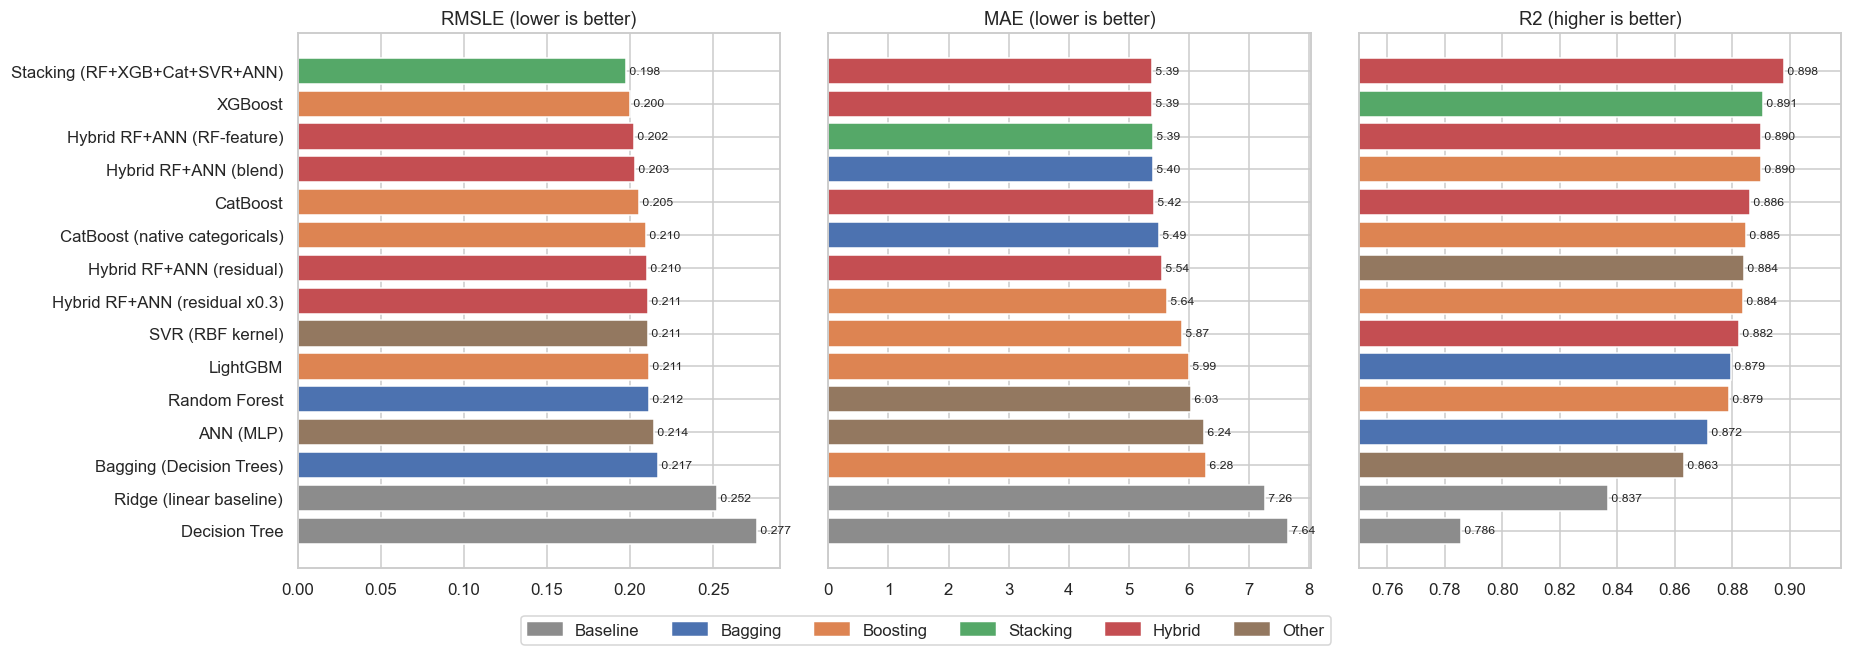

In [31]:
fam_colors = {"Baseline": "#8c8c8c", "Bagging": "#4c72b0", "Boosting": "#dd8452", "Stacking": "#55a868", "Hybrid": "#c44e52", "Other": "#937860"}
fig, ax = plt.subplots(1, 3, figsize=(17, 6))
for a, metric, asc in zip(ax, ["RMSLE", "MAE", "R2"], [True, True, False]):
    d = res.sort_values(metric, ascending=asc)
    a.barh(d.Model, d[metric], color=[fam_colors[f] for f in d.Family]); a.invert_yaxis(); a.set_title(metric + (" (lower is better)" if asc else " (higher is better)"))
    if metric == "R2": a.set_xlim(.75, d[metric].max() + .02)
    for i, v in enumerate(d[metric]): a.text(v, i, f" {v:.3f}" if metric != "MAE" else f" {v:.2f}", va="center", fontsize=8)
for a in ax[1:]: a.set_yticklabels([])
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in fam_colors.values()]
fig.legend(handles, fam_colors.keys(), loc="lower center", ncol=6); plt.tight_layout(rect=(0, .05, 1, 1)); plt.show()

Test cars per segment: {'< Rs 2.5M': 438, '2.5 - 5M': 620, '5 - 10M': 691, '> Rs 10M': 159}


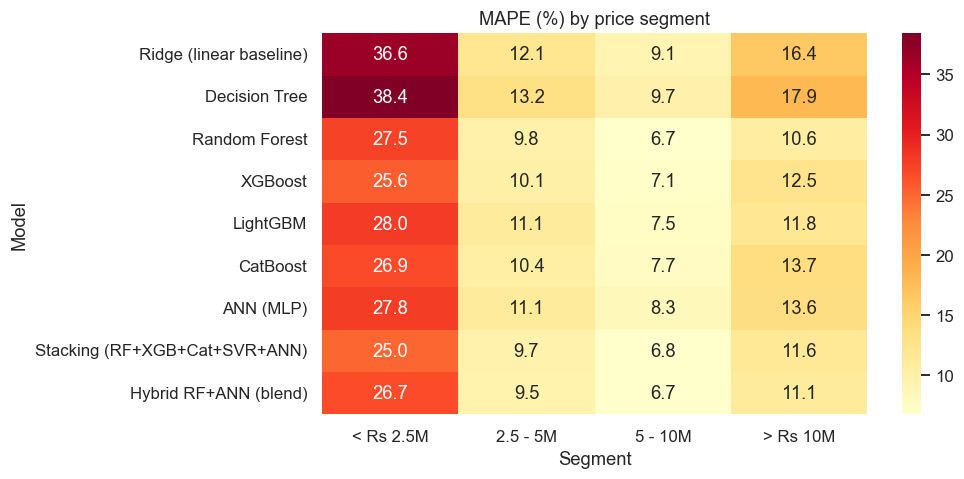

In [32]:
# error by price band
seg_bins = [0, 25, 50, 100, np.inf]; seg_labels = ["< Rs 2.5M", "2.5 - 5M", "5 - 10M", "> Rs 10M"]
seg = pd.cut(yte.values, seg_bins, labels=seg_labels)
print("Test cars per segment:", pd.Series(seg).value_counts().reindex(seg_labels).to_dict())
seg_rows = []
for name in final_models:
    for s in seg_labels:
        mk = (seg == s)
        seg_rows.append({"Model": name, "Segment": s, "MAPE_%": np.mean(np.abs(yte.values[mk] - test_pred[name][mk]) / yte.values[mk]) * 100,
                         "MAE": np.mean(np.abs(yte.values[mk] - test_pred[name][mk]))})
seg_df = pd.DataFrame(seg_rows); seg_df.to_csv("results/error_by_segment.csv", index=False)
show = ["Ridge (linear baseline)", "Decision Tree", "Random Forest", "XGBoost", "LightGBM", "CatBoost", "ANN (MLP)",
        "Stacking (RF+XGB+Cat+SVR+ANN)", best_hybrid_name]
pv = seg_df[seg_df.Model.isin(show)].pivot(index="Model", columns="Segment", values="MAPE_%")[seg_labels].loc[show]
plt.figure(figsize=(8, 4.5)); sns.heatmap(pv, annot=True, fmt=".1f", cmap="YlOrRd"); plt.title("MAPE (%) by price segment"); plt.show()

* The models are most accurate on **mid-range cars** (Rs. 5-10 M, MAPE 6.7-7.7% for the ensembles), where there is plenty of data and price follows age, brand and engine.
* **Cheap cars (under Rs. 2.5 M) have the largest percentage error** (25-28%). A few lakhs of error is a large fraction of a small price, and an old car's price depends on condition, which this dataset does not have.
* **Luxury cars (over Rs. 10 M)** are rare (159 test cars), MAPE 11-14%.
* The ensembles beat the linear model most on cheap cars (about 37% down to 25-28%), because they can fit the "old, manual, small engine" corner that a straight line cannot.


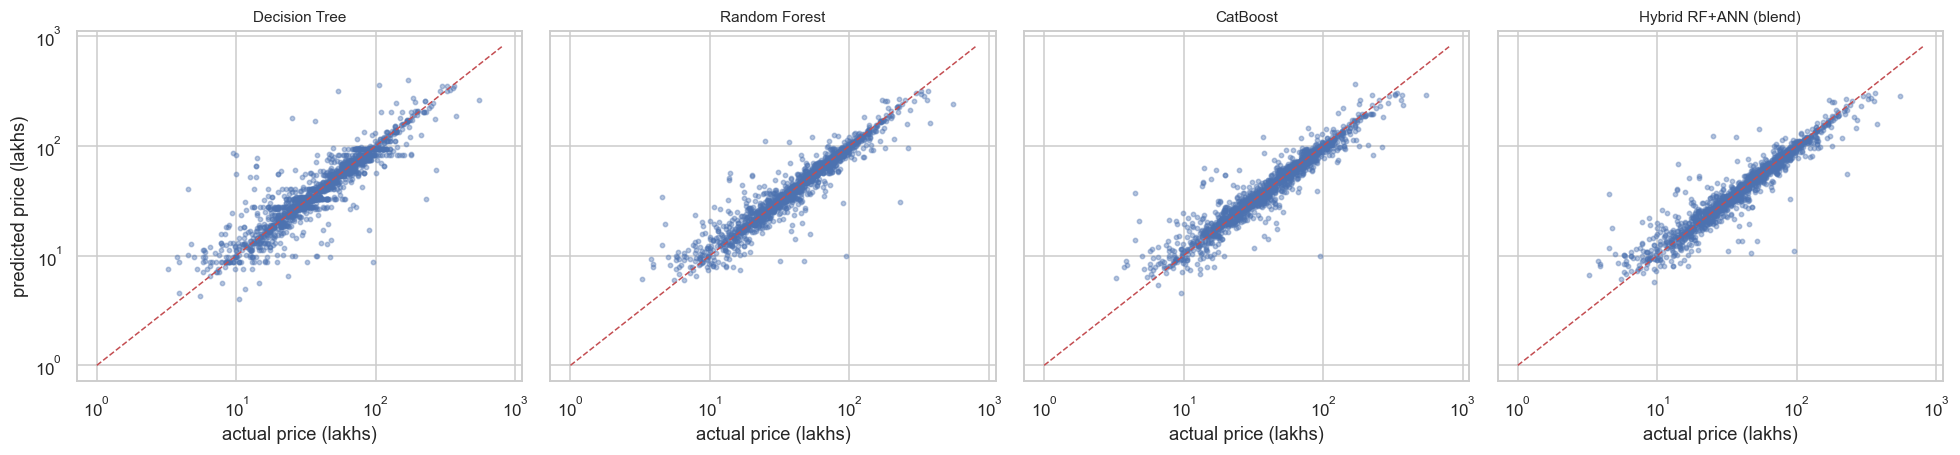

,Model,Best params,CV RMSLE,Grid size
0,Random Forest,"{'max_features': 0.33, 'min_samples_leaf': 1}",0.2228,9
1,XGBoost,"{'max_depth': 8, 'n_estimators': 400}",0.2184,6
2,LightGBM,"{'n_estimators': 400, 'num_leaves': 63}",0.2269,6
3,CatBoost,"{'depth': 8, 'l2_leaf_reg': 3}",0.2213,6
4,SVR (RBF kernel),"{'C': 3, 'gamma': 'scale'}",0.2250,6
5,ANN (MLP),"{'alpha': 0.1, 'hidden_layer_sizes': (64, 32)}",0.2313,9
6,Hybrid RF+ANN (CV-selected: Hybrid RF+ANN (ble...,"{'mode': 'blend', 'rf_weight': 0.5, 'n_ann': 3}",0.2148,4


In [33]:
# predicted vs actual for four representative models
pick = ["Decision Tree", "Random Forest", "CatBoost", best_hybrid_name]
fig, ax = plt.subplots(1, 4, figsize=(18, 4.3), sharex=True, sharey=True)
for a, n in zip(ax, pick):
    a.scatter(yte, test_pred[n], s=8, alpha=.4); lim = [1, 800]
    a.plot(lim, lim, "r--", lw=1); a.set_xscale("log"); a.set_yscale("log"); a.set_title(n, fontsize=10); a.set_xlabel("actual price (lakhs)")
ax[0].set_ylabel("predicted price (lakhs)"); plt.tight_layout(); plt.show()

# keep the test predictions for the dashboard
pd.DataFrame({"actual": yte.values, **{n: test_pred[n] for n in final_models}}).to_csv("results/test_predictions.csv", index=False)
pd.DataFrame(tuning_log).round(4)

## 10. Feature importance and interpretation

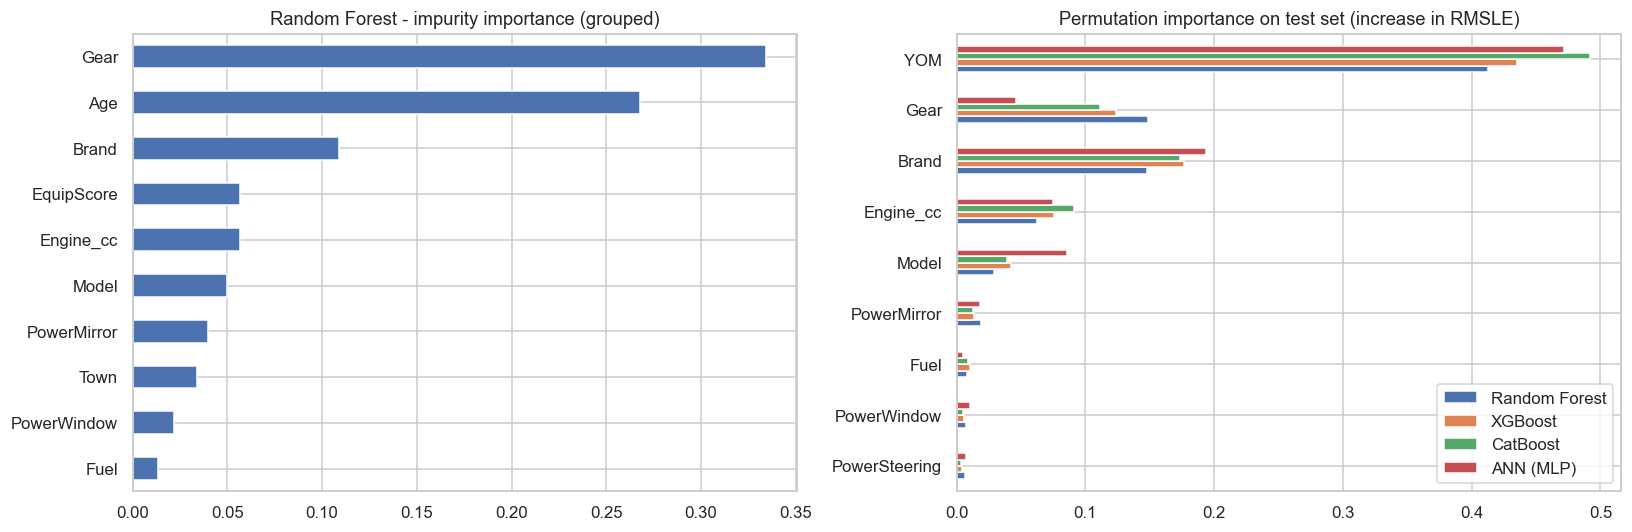

,Random Forest,XGBoost,CatBoost,ANN (MLP),Stacking (RF+XGB+Cat+SVR+ANN),Hybrid RF+ANN (blend)
YOM,0.4129,0.4351,0.4917,0.4715,0.4610,0.4387
Gear,0.1487,0.1235,0.1114,0.0459,0.0948,0.0897
Brand,0.1475,0.1763,0.1738,0.1935,0.1768,0.1741
Engine_cc,0.0622,0.0757,0.0913,0.0745,0.0701,0.0581
Model,0.0290,0.0422,0.0394,0.0860,0.0441,0.0489
PowerMirror,0.0187,0.0131,0.0128,0.0182,0.0145,0.0185
Fuel,0.0080,0.0102,0.0086,0.0048,0.0077,0.0050
PowerWindow,0.0070,0.0057,0.0047,0.0102,0.0061,0.0073
PowerSteering,0.0066,0.0043,0.0037,0.0071,0.0058,0.0065
Town,0.0041,0.0061,0.0046,0.0075,0.0053,0.0054


In [34]:
# (a) RF impurity importance, grouped back to the original columns
rf_fit = final_models["Random Forest"].regressor_
names = rf_fit.named_steps["pre"].get_feature_names_out()
imp = rf_fit.named_steps["model"].feature_importances_
def original(n):
    n = n.split("__", 1)[1]
    for c in eu.CAT_COLS:
        if n.startswith(c + "_"): return c
    return n
rf_imp = pd.Series(imp, index=[original(n) for n in names]).groupby(level=0).sum().sort_values(ascending=False)

# (b) permutation importance on the test set (shuffle the raw columns)
perm_models = ["Random Forest", "XGBoost", "CatBoost", "ANN (MLP)", "Stacking (RF+XGB+Cat+SVR+ANN)", best_hybrid_name]
perm = {}
for n in perm_models:
    r = permutation_importance(final_models[n], Xte, yte, scoring=rmsle_scorer, n_repeats=5, random_state=SEED, n_jobs=1)
    perm[n] = pd.Series(r.importances_mean, index=Xte.columns)
perm_df = pd.DataFrame(perm).sort_values("Random Forest", ascending=False)
perm_df.to_csv("results/permutation_importance.csv", index_label="feature")
rf_imp.to_csv("results/rf_impurity_importance.csv", header=["importance"], index_label="feature")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
rf_imp.head(10)[::-1].plot.barh(ax=ax[0], color="#4c72b0"); ax[0].set_title("Random Forest - impurity importance (grouped)")
perm_df[["Random Forest", "XGBoost", "CatBoost", "ANN (MLP)"]].head(9)[::-1].plot.barh(ax=ax[1]); ax[1].set_title("Permutation importance on test set (increase in RMSLE)")
plt.tight_layout(); plt.show()
perm_df.round(4)

* **Year of manufacture is the main driver** under permutation importance. Shuffling it raises the test RMSLE by 0.41-0.49, more than twice any other feature. Next are **Brand** (0.15-0.19), **Gearbox** and **Engine capacity**. All five models agree on this order, so it is the data, not one algorithm.
* Impurity importance ranks Gearbox first (0.33) and age second (0.27). The two plots disagree because impurity importance favours features that make large early splits, and it is biased towards features with many possible split points. Automatic vs manual separates cheap cars from expensive ones near the root. Permutation importance measures what actually hurts the prediction, so I trust that more. Gearbox matters, but a lot of that is because it is tied to age and the class of car.
* **Town, leasing, AC and Condition are almost irrelevant** (permutation importance near 0). `Condition` is NEW in under 1% of rows, which matches the EDA.
* The ANN depends more on the car **Model** (0.086) than the trees do (0.029). A smooth set of one-hot weights can share information across similar models, while the forest needs a split for each level.


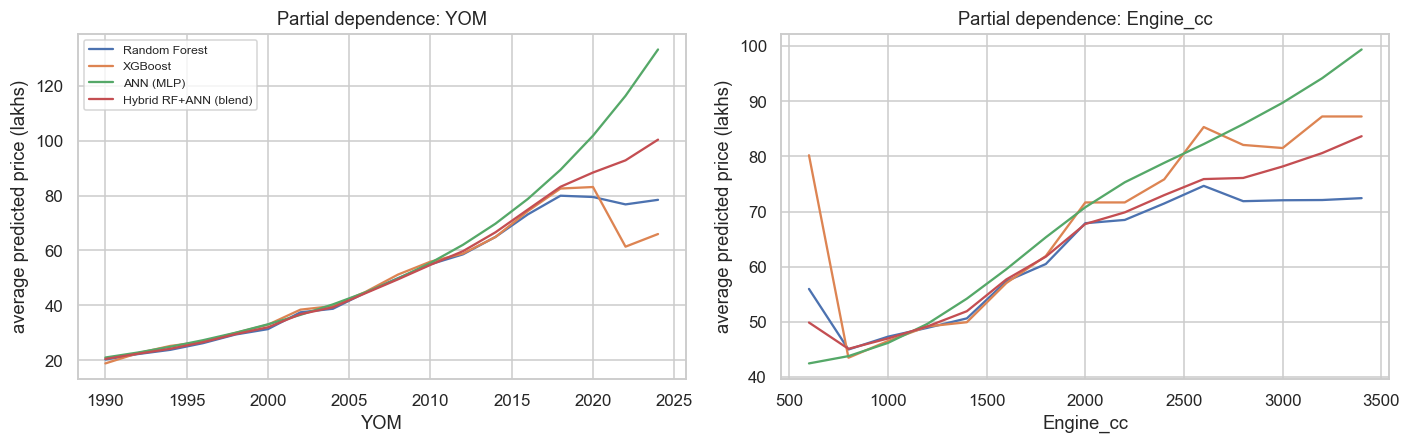

In [35]:
# (c) partial dependence, predicted price against year, and against engine size
base_car = Xte.sample(min(400, len(Xte)), random_state=SEED)
pdp_models = ["Random Forest", "XGBoost", "ANN (MLP)", best_hybrid_name]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for feat, a, grid in [("YOM", ax[0], np.arange(1990, 2025, 2)), ("Engine_cc", ax[1], np.arange(600, 3600, 200))]:
    for n in pdp_models:
        vals = []
        for g in grid:
            tmp = base_car.copy(); tmp[feat] = g; vals.append(final_models[n].predict(tmp).mean())
        a.plot(grid, vals, label=n)
    a.set_xlabel(feat); a.set_ylabel("average predicted price (lakhs)"); a.set_title("Partial dependence: " + feat)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

* All the models agree for ordinary years (1990 to about 2017), price rises smoothly, and roughly exponentially, with a newer year.
* The models disagree on the newest cars. The tree models flatten (Random Forest) or even drop (XGBoost) after about 2018, while the ANN keeps rising. There are few brand-new cars, and their price depends on brand and model, not only the year. A tree can only output values it has seen in its leaves, so **trees cannot extrapolate**. The ANN continues the trend, which can help or can overshoot (a 2024 prediction may be too high).
* For engine size the trees flatten above about 2,500 cc, again because there are few examples. The spike at 600 cc is the bad engine data from the EDA (luxury hybrids listed as 600 cc).
* This is why the dashboard shows the spread across models. When they disagree, that car is probably in a thin part of the data.


## 11. Why did the models behave like this?

### 11.1 Why some models did better on this dataset

| What happened | Why I think so |
|---|---|
| **One tree R2 0.79, forest 0.88** | A deep tree has low bias but high variance (training error near 0, CV error flat). Averaging bootstrap trees removes most of that variance, `Var = rho sigma^2 + (1 - rho) sigma^2 / B`. The OOB and `max_features` experiments match both terms. |
| **Ridge (R2 0.84) is a strong baseline** | After the log transform, price is close to additive in age, brand and engine, which a linear model can capture. The ensembles win by fitting interactions (for example automatic x hybrid x year) and the nonlinear old-car end of the data. |
| **XGBoost beats Random Forest** (RMSLE 0.200 vs 0.212) | The signal is smooth and strong (year, brand), so the limit is bias, and boosting fits residuals one tree at a time. A possible extra reason, which I did not test, the forest's deep trees have to deal with about 280 mostly empty one-hot columns, and a random subset of features will often miss the strongest ones. |
| **LightGBM and native CatBoost a bit worse** | Many leaves, and ordered target statistics on 1,555 model levels, both chase rare categories in a small dataset. Pooling rare levels helped more than the fancier categorical handling. |
| **The ANN (R2 0.88) matches the tree models** | With only 13 raw features and a smooth target, a small MLP is competitive. It is a bit weaker on mid-range and luxury cars (MAPE 8.3% vs 6.7% for the forest at Rs. 5-10 M, and 13.6% vs 10.6% above Rs. 10 M). |
| **Stacking and the hybrid win by a small margin** | They help by mixing different error patterns (tree, kernel, neural net). Base-model errors are 0.84-0.94 correlated, so the gain is small, about 7% lower RMSLE than the forest. |
| **Everything stops near RMSLE 0.20 (MAPE about 12-13%)** | This is **irreducible error**. Very different models hit the same floor, so the limit is the information, not the algorithm. Mileage is synthetic, and there is no trim, accident history, real condition, colour or seller type. An asking price is also negotiable. Better data would help more than a better model. |

### 11.2 Strengths and limits

| Method | What worked here | What did not |
|---|---|---|
| **Bagging / Random Forest** | Robust, tuning barely moved it (R2 0.87 untuned bagging, 0.88 tuned). Free OOB score. Fast (4 s). Handles outliers and mixed features with no scaling. | It only cuts variance, so it keeps the bias of its trees (XGBoost is better here). The file is large (30 MB). It cannot extrapolate past the training range. Impurity importance is biased. |
| **Boosting (XGB / LGBM / Cat)** | Best single models. Small files (under 1 MB). Fast (5 s). Learning rate and depth give control of bias. | It overfits if trees are added with no validation (the curve above). More hyperparameters. LightGBM and native CatBoost looked more sensitive to rare noisy categories. |
| **Stacking** | Best RMSLE. Any base models can be used. The meta-learner weights say who to trust. | The gain is tiny when the errors are correlated. Slow (225 s, a K-fold fit of every base model). Large file. Harder to explain. A simple average was almost as good. |
| **Hybrid RF + ANN** | Easy to build. The blend beat both parents. The ANN adds a smooth part that can extrapolate. | Residual correction fails when the residual is noise. Two models to keep. The ANN needs scaling and regularisation. Extrapolation can be wrong. |

### 11.3 Limits of this study
* **One 80/20 split.** The bootstrap intervals show uncertainty on this test set, but I did not repeat the whole experiment on many splits. The order of the top models could change.
* The prices are **asking prices, not sale prices**, from about 10 weeks (Dec 2024 to Feb 2025). The market can move.
* **Mileage is synthetic**, and Condition barely changes, so two important real-world drivers are missing.
* Near-duplicate adverts (same model, year and engine, different town) remain after the exact repeats are removed. That makes the score a bit optimistic.
* The grids were small (3-fold) to keep the runtime reasonable. A bigger search could move the numbers slightly.
* If I had more time I would get the real mileage and the trim from the advert text, split by date instead of at random, and add a range around each prediction.

### 11.4 Tables vs images and text
On a table like this one, tree ensembles are the usual choice. The columns are different kinds of measurements, many of them do not help, and the price pattern is uneven. A tree can ignore a useless column and can fit that uneven pattern. The ANN only gets close after scaling and regularisation, and it is a bit worse on mid-range and luxury cars.

On images and text it goes the other way. A tree does not know that nearby pixels belong together, or that word order matters. CNNs and Transformers learn those patterns. Trees get used there after a network has already turned the image or the text into numbers, or when the dataset is small.

The RF + ANN hybrid is a small version of that mix. The trees handle the uneven table, and the network adds a smooth part. At this data size I would not expect a deep model to clearly beat gradient boosting.


## 12. Saving models for the dashboard

In [36]:
save_map = {"Random Forest": "random_forest", "XGBoost": "xgboost", "LightGBM": "lightgbm", "CatBoost": "catboost",
            "ANN (MLP)": "ann_mlp", "Stacking (RF+XGB+Cat+SVR+ANN)": "stacking", best_hybrid_name: "hybrid_rf_ann"}
for n, f in save_map.items():
    joblib.dump(final_models[n], f"models/{f}.pkl", compress=3)
    print(f"saved models/{f}.pkl  ({os.path.getsize(f'models/{f}.pkl') / 1e6:.1f} MB)")

# dropdown values and headline numbers for the dashboard
cars = df.groupby("Brand").Model.apply(lambda s: sorted(s.value_counts()[lambda v: v >= 3].index)).to_dict()
meta = {
    "reference_year": 2025, "n_rows": int(len(df)), "price_unit": "LKR lakhs (1 lakh = Rs. 100,000)",
    "brand_models": {b: m for b, m in cars.items() if m},
    "towns": sorted(df.Town.value_counts()[lambda v: v >= 3].index),
    "yom_range": [int(df.YOM.min()), int(df.YOM.max())], "engine_range": [int(df.Engine_cc.min()), int(df.Engine_cc.max())],
    "model_files": {n: f + ".pkl" for n, f in save_map.items()},
    "best_model_by_rmsle": res.iloc[0]["Model"], "best_hybrid": best_hybrid_name,
    "median_engine_by_model": df.groupby("Model").Engine_cc.median().round().to_dict(),
}
json.dump(meta, open("models/metadata.json", "w"), indent=1)

# reload the pickles the same way the dashboard does, and predict one car
example = pd.DataFrame([dict(Brand="TOYOTA", Model="VITZ", YOM=2015, Engine_cc=1000, Gear="Automatic", Fuel="Petrol", Town="Colombo",
                             Leasing="No Leasing", Condition="USED", AC="Available", PowerSteering="Available",
                             PowerMirror="Available", PowerWindow="Available")])
for n, f in save_map.items():
    print(f"{n:34s} -> Rs. {joblib.load(f'models/{f}.pkl').predict(example)[0] / 10:.2f} million")

saved models/random_forest.pkl  (30.3 MB)
saved models/xgboost.pkl  (0.7 MB)


saved models/lightgbm.pkl  (0.8 MB)
saved models/catboost.pkl  (0.4 MB)
saved models/ann_mlp.pkl  (0.5 MB)


saved models/stacking.pkl  (32.4 MB)


saved models/hybrid_rf_ann.pkl  (32.0 MB)


Random Forest                      -> Rs. 7.62 million
XGBoost                            -> Rs. 7.44 million


LightGBM                           -> Rs. 7.66 million
CatBoost                           -> Rs. 7.43 million
ANN (MLP)                          -> Rs. 7.79 million


Stacking (RF+XGB+Cat+SVR+ANN)      -> Rs. 7.61 million


Hybrid RF+ANN (blend)              -> Rs. 7.59 million


## 13. AI usage acknowledgment and references

**AI usage acknowledgment.** I used an AI assistant (Claude, in the Cursor editor) to clarify concepts (bias-variance, OOB error, stacking, the hybrid designs) and for coding help, and the Streamlit dashboard (`app.py`), and the README. I ran the experiments, checked the outputs, and wrote the interpretation from those results.

**References**
1. Dataset, Nirmal, P. *SriLankan Vehicle (Car) Price Dataset*, Kaggle (scraped from ikman.lk and riyasewana.com), MIT licence.
2. Lecture and Lab notes, CM3720 Machine Learning (ensemble learning, bagging and random forests).
